# Delivery Delays and Customer Satisfaction in Brazilian E-commerce (Olist)

Late delivery is one of the most visible failures of an online marketplace as when the customer waits longer than promised, and the platform pays for it in reviews, repeat purchases and support costs. This project explores how delivery time relates to customer satisfaction in a marketplace using the public [Olist Brazilian E-commerce dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).

**Data.** About 100,000 orders placed on the Olist marketplace between September 2016 and October 2018, spread across linked tables (orders, customers, order_items, sellers, reviews). Delay is only defined for delivered orders, so the analysis uses delivered orders only.

**Questions**
1. Which Brazilian states most often receive orders later than the delivery date promised to the customer?
2. Are late deliveries associated with lower review scores, and does the score fall as the delay grows?
3. Are late orders concentrated among a small share of sellerі? Are there problematic sellers, and where are they located?

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
files = os.listdir(path)
print(files)
print(len(files))

['olist_customers_dataset.csv', 'olist_sellers_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_order_items_dataset.csv', 'olist_products_dataset.csv', 'olist_geolocation_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv']
9


In [4]:
orders_df = pd.read_csv(f"{path}/olist_orders_dataset.csv")
customers_df = pd.read_csv(f"{path}/olist_customers_dataset.csv")
order_items_df = pd.read_csv(f"{path}/olist_order_items_dataset.csv")
reviews_df = pd.read_csv(f"{path}/olist_order_reviews_dataset.csv")
sellers_df = pd.read_csv(f"{path}/olist_sellers_dataset.csv")


# Question 1: Which Brazilian states most often receive orders later than the delivery date promised to the customer?



**Metrics**
- `delay_days` = actual delivery date − estimated delivery date. Negative values mean the order arrived earlier than promised
- `is_delayed` = `delay_days > 0`
- `delay_rate_pct` = share of delayed orders in a state
- `median_delay_when_late` = median `delay_days` among delayed orders only

## Data preparation

Only orders with status `delivered` are kept, since delay is only defined for delivered orders. 22 rows with missing dates are dropped. Delivery timestamps are normalized to the date level, so that delay is measured in whole days and compared with the estimated date.

In [5]:
df_delays = orders_df.merge(customers_df, on = 'customer_id', how='left')

In [6]:
df_delays = df_delays.loc[df_delays['order_status'] == 'delivered', ['order_id', 'customer_id', 'order_approved_at', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_state', 'order_purchase_timestamp']]

In [7]:
df_delays.isna().sum()

,0
order_id,0
customer_id,0
order_approved_at,14
order_delivered_customer_date,8
order_estimated_delivery_date,0
customer_state,0
order_purchase_timestamp,0


In [8]:
df_delays = df_delays.dropna()

In [9]:
df_del_clean = df_delays.copy()

In [10]:
df_del_clean.head(5)

,order_id,customer_id,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,customer_state,order_purchase_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 11:07:15,2017-10-10 21:25:13,2017-10-18 00:00:00,SP,2017-10-02 10:56:33
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-26 03:24:27,2018-08-07 15:27:45,2018-08-13 00:00:00,BA,2018-07-24 20:41:37
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:55:23,2018-08-17 18:06:29,2018-09-04 00:00:00,GO,2018-08-08 08:38:49
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:45:59,2017-12-02 00:28:42,2017-12-15 00:00:00,RN,2017-11-18 19:28:06
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 22:20:29,2018-02-16 18:17:02,2018-02-26 00:00:00,SP,2018-02-13 21:18:39


In [11]:
date_cols = ['order_approved_at', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_purchase_timestamp']
for col in date_cols:
  df_del_clean[col] = pd.to_datetime(df_del_clean[col], errors='coerce')

## Data quality checks

- All dates fall within the expected period (Sep 2016 – Oct 2018) with no impossible years.
- No order was delivered before it was purchased, and no estimated date precedes the purchase date.
- 61 orders (0.06%) have a delivery date earlier than the approval date. This is a data inconsistency, but it does not affect `delay_days`, which does not use the approval date, so these rows are kept.

In [12]:
print(df_del_clean[date_cols].agg(['min', 'max']))

print('delivered earlier than purchase:', (df_del_clean['order_delivered_customer_date'] < df_del_clean['order_purchase_timestamp']).sum())
print('delivered earlier than approval:', (df_del_clean['order_delivered_customer_date'] < df_del_clean['order_approved_at']).sum())
print('estimated earlier than purchase:', (df_del_clean['order_estimated_delivery_date'] < df_del_clean['order_purchase_timestamp']).sum())


      order_approved_at order_delivered_customer_date  \
min 2016-09-15 12:16:38           2016-10-11 13:46:32   
max 2018-08-29 15:10:26           2018-10-17 13:22:46   

    order_estimated_delivery_date order_purchase_timestamp  
min                    2016-10-04      2016-09-15 12:16:38  
max                    2018-10-25      2018-08-29 15:00:37  
delivered earlier than purchase: 0
delivered earlier than approval: 61
estimated earlier than purchase: 0


In [13]:
df_del_clean.isna().sum()

,0
order_id,0
customer_id,0
order_approved_at,0
order_delivered_customer_date,0
order_estimated_delivery_date,0
customer_state,0
order_purchase_timestamp,0


In [14]:
df_del_clean['order_delivered_customer_date'] = df_del_clean['order_delivered_customer_date'].dt.normalize()

In [15]:
df_del_clean['delay_days'] = (
    df_del_clean['order_delivered_customer_date'] - df_del_clean['order_estimated_delivery_date']
).dt.days

In [16]:
df_del_clean['delay_days'].describe()

,delay_days
count,96456.000000
mean,-11.874399
std,10.181836
min,-147.000000
25%,-17.000000
50%,-12.000000
75%,-7.000000
max,188.000000


In [17]:
df_del_clean['is_delayed'] = df_del_clean['delay_days'] > 0

In [18]:
df_del_clean.sort_values(by = 'delay_days', ascending = True).head(5)

,order_id,customer_id,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,customer_state,order_purchase_timestamp,delay_days,is_delayed
40094,0607f0efea4b566f1eb8f7d3c2397320,a5fbb6579eacbeb02752a143bfe82405,2018-03-06 09:55:47,2018-03-09,2018-08-03,SP,2018-03-06 09:47:07,-147,False
15791,c72727d29cde4cf870d569bf65edabfd,964253ff0e4e08180064764a450e521f,2017-02-09 02:50:07,2017-02-14,2017-07-04,MA,2017-02-07 18:01:15,-140,False
57160,eec7f369423b033e549c02f3c5381205,32cef4bdd6bfa50612d81dc77a93b131,2018-02-08 10:10:31,2018-02-27,2018-07-12,RS,2018-02-06 20:44:56,-135,False
86444,c2bb89b5c1dd978d507284be78a04cb2,6357fffb5704244d552615bbfcea1442,2017-05-24 22:35:08,2017-06-09,2017-10-11,SP,2017-05-23 22:28:36,-124,False
67488,40dc2ba6f322a17626aac6244332828c,6210a37f9d6a265a4f3fbe2c21672a00,2017-10-05 21:49:21,2017-10-13,2018-01-30,RJ,2017-10-05 21:39:05,-109,False


In [19]:
df_del_clean.sort_values(by = 'delay_days', ascending = False).head(5)

,order_id,customer_id,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,customer_state,order_purchase_timestamp,delay_days,is_delayed
55619,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,2018-02-23 15:16:14,2018-09-19,2018-03-15,RJ,2018-02-23 14:57:35,188,True
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,2017-02-23 02:35:15,2017-09-19,2017-03-22,ES,2017-02-21 23:31:27,181,True
11399,47b40429ed8cce3aee9199792275433f,cb2caaaead400c97350c37a3fc536867,2018-01-03 10:31:15,2018-07-13,2018-01-19,SP,2018-01-03 09:44:01,175,True
81401,2fe324febf907e3ea3f2aa9650869fa5,65b14237885b3972ebec28c0f7dd2220,2017-03-13 20:17:10,2017-09-19,2017-04-05,SP,2017-03-13 20:17:10,167,True
89130,285ab9426d6982034523a855f55a885e,9cf2c3fa2632cee748e1a59ca9d09b21,2017-03-08 22:47:40,2017-09-19,2017-04-06,SE,2017-03-08 22:47:40,166,True


In [20]:
delay_result = df_del_clean.groupby('customer_state').agg(
      total_orders=('order_id', 'count'),
      delayed_orders=('is_delayed', 'sum'),
      delay_rate_pct=('is_delayed', lambda s: s.mean() * 100),
      avg_delay_days_when_late=('delay_days', lambda s: s[s > 0].mean()),
      max_days_early=('delay_days', lambda s: -s.min()),
      median_days_vs_estimate=('delay_days', 'median'),
      median_delay_when_late=('delay_days', lambda s: s[s > 0].median())
  ).round(2).reset_index()

In [21]:
delay_result.sort_values(by='delay_rate_pct', ascending = False)

,customer_state,total_orders,delayed_orders,delay_rate_pct,avg_delay_days_when_late,max_days_early,median_days_vs_estimate,median_delay_when_late
1,AL,397,85,21.41,9.54,69,-10.0,7.0
9,MA,716,125,17.46,10.50,140,-10.5,8.0
24,SE,335,51,15.22,16.20,41,-13.0,9.0
16,PI,476,66,13.87,13.35,46,-14.0,6.0
5,CE,1278,176,13.77,15.18,76,-13.0,10.0
21,RR,41,5,12.20,36.40,58,-20.0,10.0
4,BA,3256,396,12.16,12.02,65,-12.0,7.0
18,RJ,12348,1495,12.11,13.52,109,-13.0,9.0
13,PA,946,106,11.21,12.82,60,-16.0,9.0
7,ES,1995,214,10.73,11.30,78,-12.0,6.0


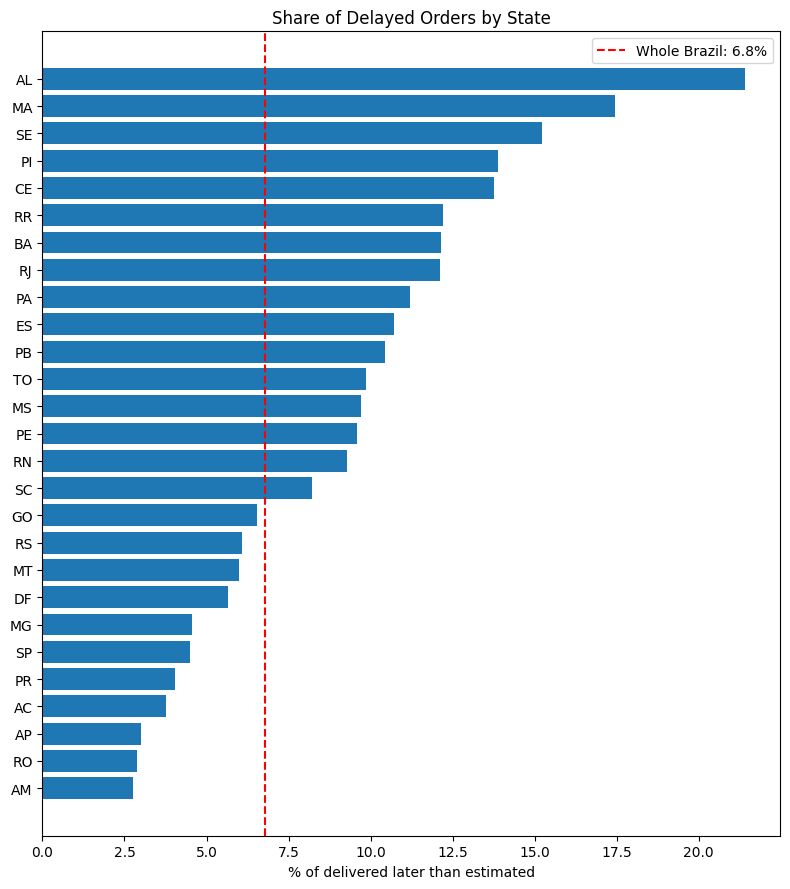

In [22]:
overall = df_del_clean['is_delayed'].mean() * 100
plot_df = delay_result.sort_values('delay_rate_pct')

plt.figure(figsize=(8, 9))
plt.barh(plot_df['customer_state'], plot_df['delay_rate_pct'])
plt.axvline(overall, color='red', linestyle='--', label=f'Whole Brazil: {overall:.1f}%')
plt.xlabel('% of delivered later than estimated')
plt.title('Share of Delayed Orders by State')
plt.legend()
plt.tight_layout()
plt.show()

About 6.8% of all orders arrive later than promised, but the rate varies strongly by state. It is highest in the north-east (Alagoas 21.4%, Maranhão 17.5%, Sergipe 15.2%, Piauí 13.9%, Ceará 13.8%) and lowest in the south-east and south (São Paulo 4.5%, Minas Gerais 4.6%, Paraná 4.0%) and other small states. Alagoas has roughly  5 times the delay rate of São Paulo.

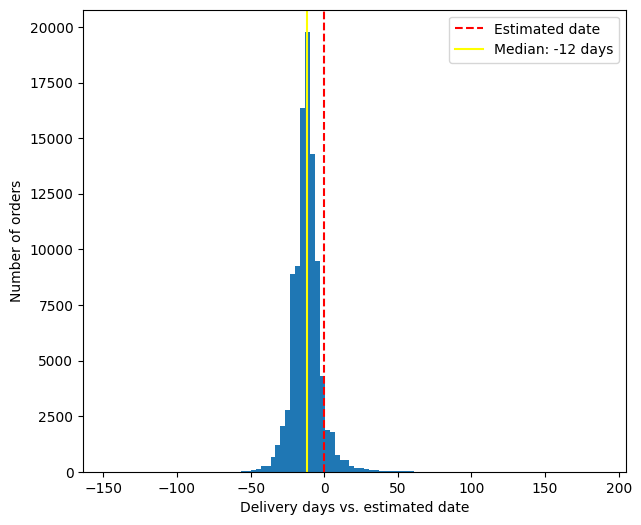

In [23]:
median_delay = df_del_clean['delay_days'].median()

plt.figure(figsize=(7, 6))
plt.hist(df_del_clean['delay_days'], bins=100)
plt.axvline(0, color='red', linestyle='--', label='Estimated date')
plt.axvline(median_delay, color='yellow', linestyle='-', label=f'Median: {median_delay:.0f} days')
plt.xlabel('Delivery days vs. estimated date')
plt.ylabel('Number of orders')
plt.legend()
plt.show()

 Most orders arrive well before the estimated date as the median order is delivered 12 days early. The estimated delivery date includes a large safety buffer, and late deliveries are the exception rather than the rule.

# Question 2: Are late deliveries associated with lower review scores, and does the score fall as the delay grows?





**Data:** delivered orders from Part 1 joined with the `order_reviews` table (review score from 1 to 5).

**Metrics**
- `mean_score` = average review score.
- `pct_low_score` = share of reviews with 1 or 2 stars.
- `delay_bucket` = delay grouped into ranges: on time or early, 1-3, 4-7, 8-14 and 15+ days late.

### Data preparation

Some orders have more than one review. To avoid counting an order twice, only the latest review per order is kept. Orders without a review are excluded from the score statistics.

In [24]:
reviews_df.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [25]:
reviews_df['order_id'].duplicated().sum()

np.int64(551)

In [26]:
reviews_df['review_score'].describe()

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [27]:
reviews_latest = (reviews_df.sort_values('review_answer_timestamp')
                  .drop_duplicates('order_id', keep='last'))


In [28]:
del_rw_df = df_del_clean.merge(
    reviews_latest, on='order_id', how='left', validate='one_to_one')

In [29]:
del_rw_df = del_rw_df[['order_id', 'customer_state', 'delay_days', 'is_delayed', 'review_score']]

In [30]:
del_rw_df.isna().sum()

,0
order_id,0
customer_state,0
delay_days,0
is_delayed,0
review_score,646


In [31]:
del_rw_df = del_rw_df.dropna()

In [32]:
df_rev_states = del_rw_df.groupby('customer_state').agg(
    mean_score = ('review_score', 'mean'),
    median_score = ('review_score', 'median')
).reset_index().round(2)

In [33]:
df_rev_states.sort_values('mean_score')

,customer_state,mean_score,median_score
9,MA,3.83,4.0
1,AL,3.85,4.0
21,RR,3.90,4.0
13,PA,3.91,5.0
24,SE,3.91,5.0
4,BA,3.93,5.0
5,CE,3.94,5.0
18,RJ,3.97,5.0
16,PI,3.99,5.0
14,PB,4.08,5.0


In [34]:
df_rev_if_delayed = del_rw_df.groupby('is_delayed').agg(
    count = ('review_score', 'count'),
    mean_score = ('review_score', 'mean'),
    median_score = ('review_score', 'median')
).reset_index().round(2)

In [35]:
df_rev_if_delayed

,is_delayed,count,mean_score,median_score
0,False,89429,4.29,5.0
1,True,6381,2.27,1.0


In [36]:
bins = [-float('inf'), 0, 3, 7, 14, float('inf')]
labels = ['On time or early', '1-3 days late', '4-7 days late', '8-14 days late', '15+ days late']
del_rw_df['delay_bucket'] = pd.cut(del_rw_df['delay_days'], bins=bins, labels=labels)

In [37]:
df_rev_bucket = del_rw_df.groupby('delay_bucket', observed=True).agg(
    orders=('review_score', 'count'),
    mean_score=('review_score', 'mean'),
    pct_low_score=('review_score', lambda s: (s <= 2).mean() * 100)
).round(2).reset_index()

In [38]:
df_rev_bucket

,delay_bucket,orders,mean_score,pct_low_score
0,On time or early,89429,4.29,9.27
1,1-3 days late,1852,3.29,32.13
2,4-7 days late,1748,2.10,67.68
3,8-14 days late,1446,1.67,80.15
4,15+ days late,1335,1.72,78.35


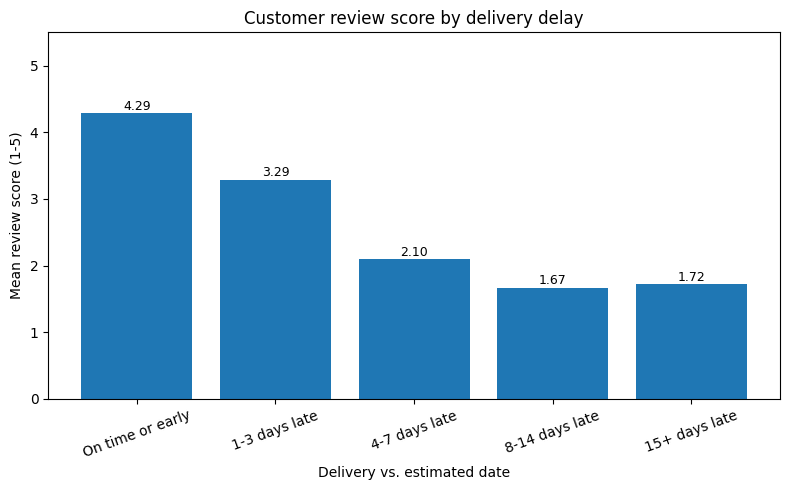

In [39]:
plt.figure(figsize=(8, 5))
bars = plt.bar(df_rev_bucket['delay_bucket'].astype(str), df_rev_bucket['mean_score'])
for bar, score in zip(bars, df_rev_bucket['mean_score']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
             f'{score:.2f}', ha='center', fontsize=9)
plt.ylim(0, 5.5)
plt.xlabel('Delivery vs. estimated date')
plt.ylabel('Mean review score (1-5)')
plt.title('Customer review score by delivery delay')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

 Orders delivered on time or early have a mean score of 4.29, while orders delivered 15+ days late have 1.72. The score drops as the delay grows and then stays at about 1.7 for longer delays.

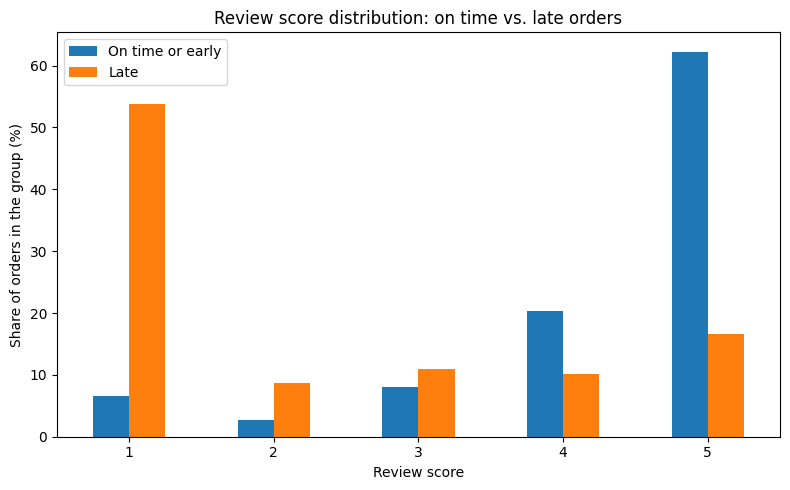

In [40]:
rated = del_rw_df.dropna(subset=['review_score']).copy()
rated['review_score'] = rated['review_score'].astype(int)

dist = (
    rated.groupby('is_delayed')['review_score']
         .value_counts(normalize=True).mul(100)
         .unstack(0).sort_index()
)
dist.columns = ['On time or early', 'Late']

dist.plot(kind='bar', figsize=(8, 5))
plt.xlabel('Review score')
plt.ylabel('Share of orders in the group (%)')
plt.title('Review score distribution: on time vs. late orders')
plt.xticks(rotation=0)
plt.legend(title='')
plt.tight_layout()
plt.show()

About 62% of on-time orders receive 5 stars, compared with about 17% of late orders. In the opposite, about 54% of late orders receive 1 star versus about 6% of on-time orders, so a late delivery makes a 1-star review roughly 9 times more likely.

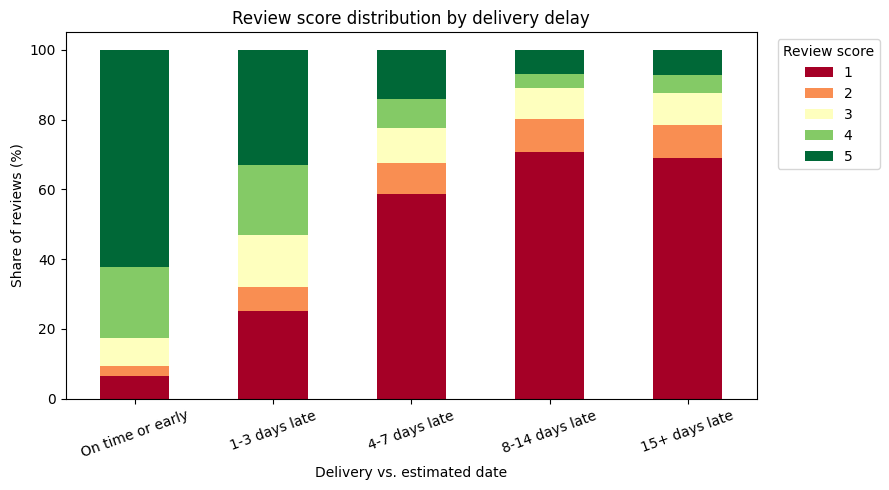

In [41]:
rated = del_rw_df.dropna(subset=['review_score']).copy()
rated['review_score'] = rated['review_score'].astype(int)

score_share = pd.crosstab(rated['delay_bucket'], rated['review_score'], normalize='index') * 100

score_share.plot(kind='bar', stacked=True, figsize=(9, 5), colormap='RdYlGn')
plt.xlabel('Delivery vs. estimated date')
plt.ylabel('Share of reviews (%)')
plt.title('Review score distribution by delivery delay')
plt.xticks(rotation=20)
plt.legend(title='Review score', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

The share of low scores (1-2 stars) grows from 9% for on-time orders to 32% for 1-3 days late and 68% for 4-7 days late, then remains the same at about 80%.

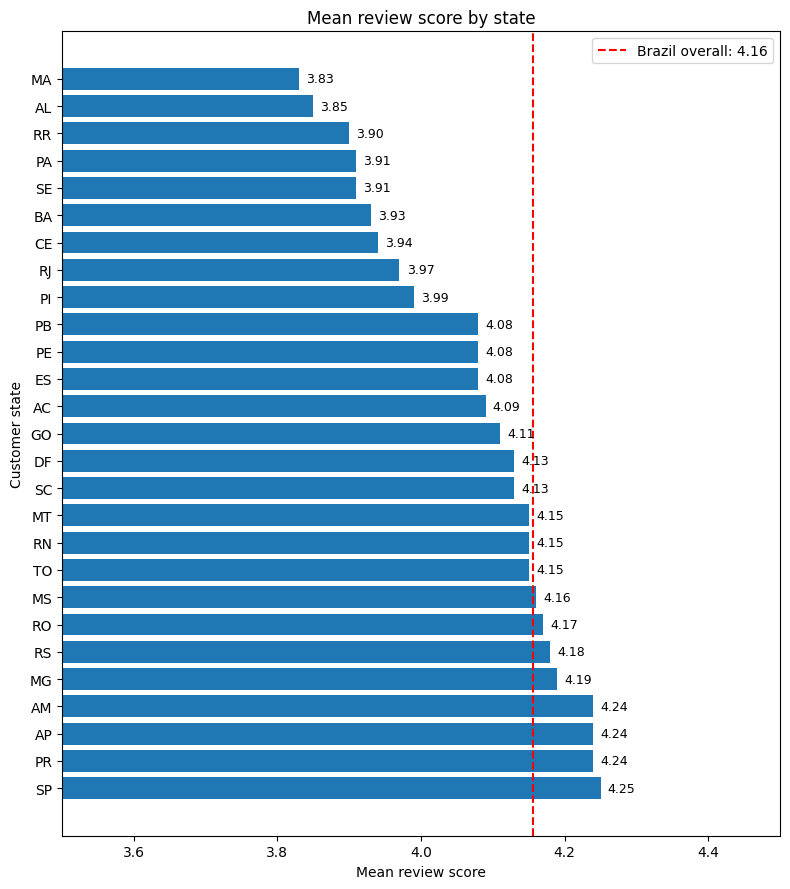

In [42]:
plot_df = df_rev_states.sort_values('mean_score', ascending=True)
overall = del_rw_df['review_score'].mean()

plt.figure(figsize=(8, 9))
bars = plt.barh(plot_df['customer_state'], plot_df['mean_score'])
for bar, v in zip(bars, plot_df['mean_score']):
    plt.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f'{v:.2f}', va='center', fontsize=9)
plt.axvline(overall, color='red', linestyle='--', label=f'Brazil overall: {overall:.2f}')
plt.xlim(3.5, 4.5)
plt.xlabel('Mean review score')
plt.ylabel('Customer state')
plt.title('Mean review score by state')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Mean review scores range only from 3.83 to 4.25 across states, so differences are small, but the ranking is clear. The lowest scores are in Maranhao (3.83), Alagoas (3.85), Para, Sergipe, Bahia and Ceara (3.91-3.94), mostly the same north-eastern states with the highest share of late orders in Part 1. The highest scores are in the south-east and south (Sao Paulo 4.25, Parana 4.24), which had the fewest late orders.

# Question 3: Are late orders concentrated among a small share of sellers? Are there problematic sellers, and where are they located?

**Metrics**
- `orders_count` = number of delivered, reviewed orders of sellers
- `delayed` = number of those orders delivered later than the estimated date
- `delay_rate_pct` = share of delayed orders of a seller.
- `cum_share_delays` / `cum_share_orders` = cumulative share of all late orders / all orders, with sellers sorted from most to fewest late orders
- `cum_share_sellers` = cumulative share of sellers in the same ordering
- **Problematic seller** = a seller with at least 30 orders and a delay rate of 15% or more

In [43]:
order_items_df.nunique()

,0
order_id,98666
order_item_id,21
product_id,32951
seller_id,3095
shipping_limit_date,93318
price,5968
freight_value,6999


In [44]:
items = order_items_df[['order_id', 'seller_id']].drop_duplicates()

In [45]:
single_items = items.drop_duplicates('order_id', keep=False)

In [46]:
single_items.nunique()

,0
order_id,97388
seller_id,3078


In [47]:
sell_df = del_rw_df.merge(single_items, on= 'order_id', how='inner').merge(sellers_df[['seller_id', 'seller_state']], on='seller_id', how='left')

In [48]:
sell_df

,order_id,customer_state,delay_days,is_delayed,review_score,delay_bucket,seller_id,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,SP,-8,False,4.0,On time or early,3504c0cb71d7fa48d967e0e4c94d59d9,SP
1,53cdb2fc8bc7dce0b6741e2150273451,BA,-6,False,4.0,On time or early,289cdb325fb7e7f891c38608bf9e0962,SP
2,47770eb9100c2d0c44946d9cf07ec65d,GO,-18,False,5.0,On time or early,4869f7a5dfa277a7dca6462dcf3b52b2,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,-13,False,5.0,On time or early,66922902710d126a0e7d26b0e3805106,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,-10,False,5.0,On time or early,2c9e548be18521d1c43cde1c582c6de8,SP
...,...,...,...,...,...,...,...,...
94544,9c5dedf39a927c1b2549525ed64a053c,SP,-11,False,5.0,On time or early,e24fc9fcd865784fb25705606fe3dfe7,SP
94545,63943bddc261676b46f01ca7ac2f7bd8,SP,-2,False,4.0,On time or early,1f9ab4708f3056ede07124aad39a2554,SP
94546,83c1379a015df1e13d02aae0204711ab,BA,-6,False,5.0,On time or early,d50d79cb34e38265a8649c383dcffd48,SP
94547,11c177c8e97725db2631073c19f07b62,RJ,-21,False,2.0,On time or early,a1043bafd471dff536d0c462352beb48,MG


In [49]:
sell_df.isna().sum()

,0
order_id,0
customer_state,0
delay_days,0
is_delayed,0
review_score,0
delay_bucket,0
seller_id,0
seller_state,0


In [50]:
seller_stats = sell_df.groupby('seller_id').agg(
    orders_count=('order_id', 'count'),
    delayed=('is_delayed', 'sum'),
    mean_score=('review_score', 'mean')
).reset_index()

In [51]:
seller_stats['delay_rate_pct'] = seller_stats['delayed'] / seller_stats['orders_count'] * 100

In [52]:
seller_stats = seller_stats.merge(
    sellers_df[['seller_id', 'seller_state']],
    on='seller_id', how='left', validate='one_to_one')

In [53]:
seller_stats.describe()

,orders_count,delayed,mean_score,delay_rate_pct
count,2944.000000,2944.000000,2944.000000,2944.000000
mean,32.115829,2.163383,4.223172,6.962842
std,102.707065,7.851458,0.752571,15.701395
min,1.000000,0.000000,1.000000,0.000000
25%,2.000000,0.000000,4.000000,0.000000
50%,7.000000,0.000000,4.333333,0.000000
75%,22.000000,1.000000,4.750000,7.813772
max,1774.000000,166.000000,5.000000,100.000000


In [54]:
s = seller_stats.sort_values('delayed', ascending=False).reset_index(drop=True)

In [55]:
s['cum_share_delays'] = s['delayed'].cumsum() / s['delayed'].sum() * 100

In [56]:
s['cum_share_sellers'] = (s.index + 1) / len(s) * 100

In [57]:
s['cum_share_orders'] = s['orders_count'].cumsum() / s['orders_count'].sum() * 100

In [58]:
threshold = s[s['cum_share_delays'] <= 20]
threshold.sort_values(by = 'cum_share_delays')

,seller_id,orders_count,delayed,mean_score,delay_rate_pct,seller_state,cum_share_delays,cum_share_sellers,cum_share_orders
0,4a3ca9315b744ce9f8e9374361493884,1655,166,3.909366,10.030211,SP,2.606375,0.033967,1.750415
1,1f50f920176fa81dab994f9023523100,1359,121,4.181751,8.903606,SP,4.506202,0.067935,3.187765
2,4869f7a5dfa277a7dca6462dcf3b52b2,1103,116,4.177697,10.516772,SP,6.327524,0.101902,4.354356
3,ea8482cd71df3c1969d7b9473ff13abc,1110,95,4.054054,8.558559,SP,7.819124,0.135870,5.528350
4,6560211a19b47992c3666cc44a7e94c0,1774,94,4.000564,5.298760,SP,9.295023,0.169837,7.404626
5,cc419e0650a3c5ba77189a1882b7556a,1642,87,4.154080,5.298417,SP,10.661014,0.203804,9.141292
6,7c67e1448b00f6e969d365cea6b010ab,957,87,3.510972,9.090909,SP,12.027006,0.237772,10.153465
7,da8622b14eb17ae2831f4ac5b9dab84a,1267,83,4.222573,6.550908,SP,13.330193,0.271739,11.493511
8,8b321bb669392f5163d04c59e235e066,913,80,4.122673,8.762322,SP,14.586277,0.305707,12.459148
9,955fee9216a65b617aa5c0531780ce60,1244,75,4.209807,6.028939,SP,15.763856,0.339674,13.774868


14 sellers (0.5% of all sellers) are responsible for 20% of all late orders. But they also handle about 16% of all orders. 12 of the 14 are in Sao Paulo, one in RJ and one in Maranhão. Their delay rates are mostly 5–12%, like the marketplace average. The only clear exception is the seller from Maranhão  with 18.5%. So the top of this ranking is made mostly of large sellers, not of bad ones.

In [59]:
big = seller_stats[seller_stats['orders_count'] >= 30]
big.sort_values('delay_rate_pct', ascending=False).head(10)

,seller_id,orders_count,delayed,mean_score,delay_rate_pct,seller_state
1993,ad781527c93d00d89a11eecd9dcad7c1,33,12,3.363636,36.363636,SP
2740,ede0c03645598cdfc63ca8237acbe73d,42,13,3.571429,30.952381,SP
990,54965bbe3e4f07ae045b90b0b8541f52,68,20,3.176471,29.411765,PR
1542,835f0f7810c76831d6c7d24c7a646d4d,40,11,3.475000,27.500000,SP
472,2a1348e9addc1af5aaa619b1a3679d6b,44,12,3.272727,27.272727,MG
2191,beadbee30901a7f61d031b6b686095ad,63,15,3.936508,23.809524,SP
1911,a49928bcdf77c55c6d6e05e09a9b4ca5,93,21,3.086022,22.580645,SP
2755,ef990a83bbea832f36ebe81376335aa8,40,9,3.750000,22.500000,SC
732,3fd1e727ba94cfe122d165e176ce7967,34,7,4.000000,20.588235,SP
1322,71039d19d4303bf9054d69e9a9236699,34,7,3.882353,20.588235,SP


In [61]:
big = seller_stats[seller_stats['orders_count'] >= 30]
problematic = big[big['delay_rate_pct'] >= 15]
print(len(problematic), 'of', len(big))
print(problematic['seller_state'].value_counts())
print(big['seller_state'].value_counts(normalize=True).head())

35 of 614
seller_state
SP    25
PR     3
MG     2
RJ     2
SC     2
MA     1
Name: count, dtype: int64
seller_state
SP    0.649837
MG    0.104235
PR    0.091205
SC    0.047231
RJ    0.045603
Name: proportion, dtype: float64


Among sellers with at least 30 orders, the highest delay rates are 20.6–36.4%, 3-5 times the marketplace average. These are mid sized sellers (33–93 orders). 25 of the 35 are in  Sao Paulo, the others in Paraná, Minas Gerais and Santa Catarina. Their mean review score is 3.1–4, mostly below the overall 4.2.

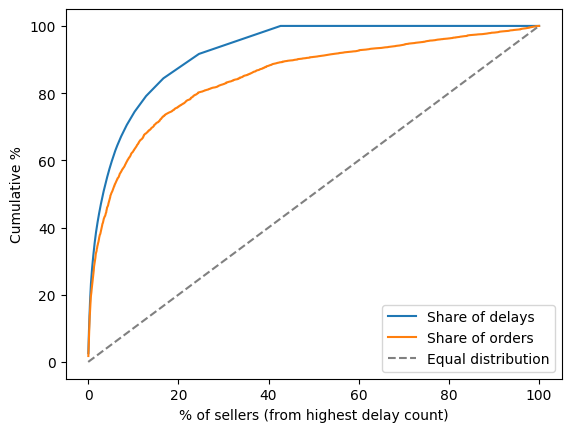

In [60]:
plt.plot(s['cum_share_sellers'], s['cum_share_delays'], label='Share of delays')
plt.plot(s['cum_share_sellers'], s['cum_share_orders'], label='Share of orders')
plt.plot([0, 100], [0, 100], linestyle='--', color='gray', label='Equal distribution')
plt.xlabel('% of sellers (from highest delay count)')
plt.ylabel('Cumulative %')
plt.legend()
plt.show()

The curve of late orders lies above the curve of orders, so late orders are concentrated, but only moderately. About 10% of sellers account for roughly 70% of late orders, against roughly 60% of all orders. About 58% of sellers have no late order at all. Because the two curves are close, most of the concentration comes from seller size, not from systematically worse delivery.

# Conclusions

**1. Late delivery is rare overall, but unequally distributed by region.** 6.8% of delivered orders arrive after the estimated date, and the typical order arrives 12 days early, so the estimate contains a large safety buffer. The delay rate is highest in the north-east (Alagoas 21.4%, Maranhão 17.5%, Sergipe 15.2%) and lowest in São Paulo (4.5%), Minas Gerais (4.6%) and Paraná (4.0%). Rio de Janeiro (12.1%) is an exception in the south-east and because of its volume (12,348 orders) it is not a small noise. The cause is not explored here.

**2. A late order is strongly associated with a bad review.** The mean score is 4.29 for on-time orders and 2.27 for late ones. The share of low scores (1-2 stars) rises from 9% to 32% after 1-3 days of delay and 68% after 4-7 days, then levels at about 80%. The first days of delay matter most. At state level, the lowest scores (Maranhão 3.83, Alagoas 3.85) are in the same north-eastern states with the most late orders.

**3. Late orders are concentrated among large sellers, but problematic sellers are a different group.**  14 sellers with the most late orders cause 20% of all delays, but they also have 16% of all orders and their delay rates are close to average. Sellers with a truly high delay rate (20–36%) are mid sized and mostly located in San Paolo, where most sellers are.

**Limitations**
- The analysis shows association, not causation. Reviews also depend on the product and the seller and 646 delivered orders have no reviews.
- Delay is only applied to a seller, but part of it may come from the carrier or the distance.
- Only delivered orders and single-seller orders are analyzed.
- Small states have a small amount of orders so may produce noisy results.

**Recommendations**
- Focus on the first few days of the delay as they play the biggest role in a review score decrease
- Review how the estimated delivery date is calculated. The median order arrives 12 days early, so the estimate is too pessimistic in most cases.
- Monitor sellers by delay rate (30+ orders and 15%+ late), not by the number of late orders as the sellers with the most late orders are just the biggest ones.